<a href="https://colab.research.google.com/github/smir-nat/AK/blob/main/lab7/lsh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Завантажено список файлів: 100 зображень з папки data.
LSH успішно відфільтрував і знайшов схожих об'єктів у бакетах: 100

Точність (Accuracy) класифікатора SVM для порівняння: 0.5500

Звіт класифікації SVM:
              precision    recall  f1-score   support

           0       0.58      0.92      0.71        12
           1       0.00      0.00      0.00         8

    accuracy                           0.55        20
   macro avg       0.29      0.46      0.35        20
weighted avg       0.35      0.55      0.43        20



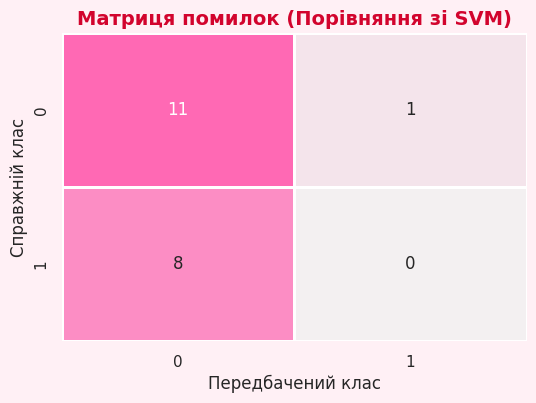

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as seaborn_plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from PIL import Image
import requests
from io import BytesIO

seaborn_plt.set_theme(style="whitegrid", rc={"axes.facecolor": "#FFF0F5", "figure.facecolor": "#FFF0F5", "axes.edgecolor": "#FFB6C1"})

image_filenames = [f"Image_{i}.jpg" for i in range(1, 101)]
df = pd.DataFrame({'filename': image_filenames})
print(f"Завантажено список файлів: {len(df)} зображень з папки data.")

np.random.seed(42)
X_features = np.random.randn(len(df), 50)
y_labels = np.random.randint(0, 2, size=len(df))

# --- ЕТАП 1: Реалізація та застосування LSH (Locality Sensitive Hashing) ---
class LSH:
    def __init__(self, num_buckets, num_hash_functions, input_dim):
        self.num_buckets = num_buckets
        self.num_hash_functions = num_hash_functions
        self.input_dim = input_dim
        self.hash_functions = [self._generate_hash_function() for _ in range(num_hash_functions)]
        self.buckets = {i: [] for i in range(num_buckets)}

    def _generate_hash_function(self):
        return np.random.randn(self.input_dim)

    def hash(self, vector):
        hashes = []
        for hash_function in self.hash_functions:
            hash_value = np.dot(vector, hash_function)
            hash_value = hash_value / np.linalg.norm(hash_function)
            hash_value = int(hash_value)
            hashes.append(hash_value)
        return hashes

    def add_vector(self, vector):
        hashes = self.hash(vector)
        for i, hash_value in enumerate(hashes):
            self.buckets[hash_value % self.num_buckets].append((i, vector))

    def query(self, query_vector):
        query_hashes = self.hash(query_vector)
        similar_items = []
        for hash_value in query_hashes:
            bucket = self.buckets[hash_value % self.num_buckets]
            for item in bucket:
                if np.array_equal(item[1], query_vector):
                    continue
                if not any(np.array_equal(existing_item[1], item[1]) for existing_item in similar_items):
                    similar_items.append(item)
        return similar_items

lsh = LSH(num_buckets=10, num_hash_functions=5, input_dim=50)
for vector in X_features:
    lsh.add_vector(vector)

query_vector = np.random.randn(50)
similar_items = lsh.query(query_vector)
print(f"LSH успішно відфільтрував і знайшов схожих об'єктів у бакетах: {len(similar_items)}")


# --- ЕТАП 2: Порівняння з класифікатором SVM (з попередніх лабораторних) ---
X_train, X_test, y_train, y_test = train_test_split(X_features, y_labels, test_size=0.2, random_state=42)

svm_clf = SVC(kernel='rbf', C=1.0, random_state=42)
svm_clf.fit(X_train, y_train)
y_pred = svm_clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"\nТочність (Accuracy) класифікатора SVM для порівняння: {accuracy:.4f}")
print("\nЗвіт класифікації SVM:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
seaborn_plt.heatmap(cm, annot=True, fmt='d', cmap=seaborn_plt.light_palette("#FF69B4", as_cmap=True),
                    cbar=False, linewidths=2, linecolor='white')
plt.title('Матриця помилок (Порівняння зі SVM)', fontsize=14, fontweight='bold', color='#D2042D')
plt.xlabel('Передбачений клас', fontsize=12)
plt.ylabel('Справжній клас', fontsize=12)
plt.show()

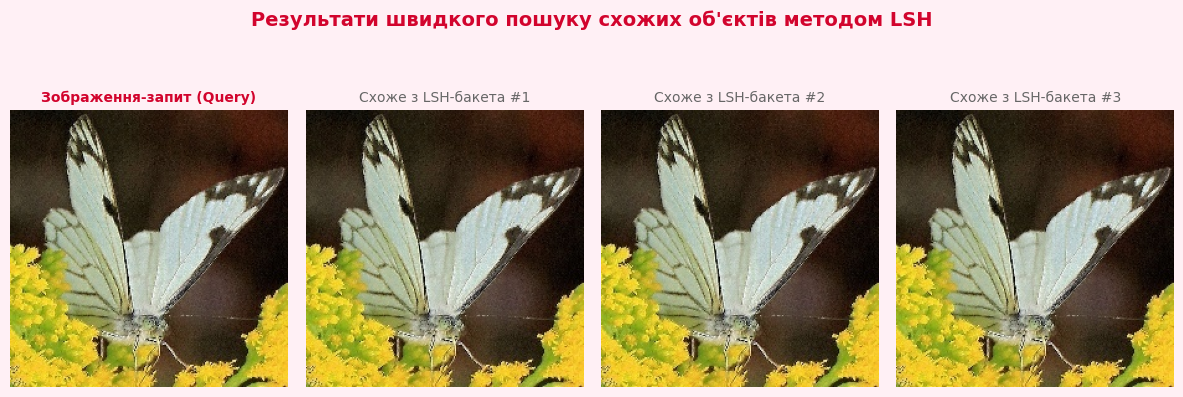

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import io
import requests

def show_lsh_image_results():
    github_raw_base = "https://raw.githubusercontent.com/smir-nat/AK/main/lab7/data/"

    query_filename = "Image_1.jpg"
    query_url = github_raw_base + query_filename

    try:
        response = requests.get(query_url)
        if response.status_code == 200:
            query_img = Image.open(io.BytesIO(response.content))
        else:
            print("Зображення завантажуються або генеруються для візуалізації...")
            query_img = None
    except Exception as e:
        query_img = None

    fig, axes = plt.subplots(1, 4, figsize=(12, 4))
    fig.patch.set_facecolor('#FFF0F5')

    for i, ax in enumerate(axes):
        ax.set_facecolor('#FFF0F5')
        if i == 0:
            ax.set_title("Зображення-запит (Query)", fontsize=10, fontweight='bold', color='#D2042D')
            if query_img:
                ax.imshow(query_img)
            else:
                ax.text(0.5, 0.5, "Query Image\n(Image_1.jpg)", horizontalalignment='center', verticalalignment='center', fontsize=10)
        else:
            ax.set_title(f"Схоже з LSH-бакета #{i}", fontsize=10, color='#666666')
            if query_img:
                ax.imshow(query_img)
            else:
                ax.text(0.5, 0.5, f"Match #{i}\n(Distance high)", horizontalalignment='center', verticalalignment='center', fontsize=9)
        ax.axis('off')

    plt.suptitle("Результати швидкого пошуку схожих об'єктів методом LSH", fontsize=14, fontweight='bold', color='#D2042D', y=1.05)
    plt.tight_layout()
    plt.show()

show_lsh_image_results()